In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt

# ── Column names 
col_names = ['unit', 'cycle', 'op1', 'op2', 'op3'] + [f's{i}' for i in range(1, 22)]

# ── Load dataset
train_df = pd.read_csv('train_FD001.txt', sep=r'\s+', header=None, names=col_names, engine='python')
test_df  = pd.read_csv('test_FD001.txt',  sep=r'\s+', header=None, names=col_names, engine='python')
rul_df   = pd.read_csv('RUL_FD001.txt',   sep=r'\s+', header=None, names=['RUL'],    engine='python')

# ── Verify correct number of engines
print(f"Train engines : {train_df['unit'].nunique()}")   # should be 100
print(f"Test engines  : {test_df['unit'].nunique()}")    # should be 100
print(f"RUL entries   : {len(rul_df)}")                  # should be 100

# ── Compute RUL for training data
MAX_RUL = 125

def add_rul(df):
    max_cycle = df.groupby('unit')['cycle'].max().reset_index()
    max_cycle.columns = ['unit', 'max_cycle']
    df = df.merge(max_cycle, on='unit')
    df['RUL'] = df['max_cycle'] - df['cycle']
    df['RUL'] = df['RUL'].clip(upper=MAX_RUL)
    df.drop(columns=['max_cycle'], inplace=True)
    return df

train_df = add_rul(train_df)

# ── Drop low-variance sensors
drop_sensors = ['s1','s5','s6','s10','s16','s18','s19']
drop_cols    = ['op3'] + drop_sensors

train_df.drop(columns=drop_cols, inplace=True)
test_df.drop(columns=drop_cols, inplace=True)

# ── Feature list
feature_cols = [c for c in train_df.columns
                if c not in ['unit', 'cycle', 'RUL']]

# ── Normalize features 
scaler = MinMaxScaler()
train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols]  = scaler.transform(test_df[feature_cols])

Train engines : 100
Test engines  : 100
RUL entries   : 100


In [2]:
# ── Loading FD002, FD003, FD004 test data
test_df2 = pd.read_csv('test_FD002.txt', sep=r'\s+', header=None, names=col_names, engine='python')
test_df3 = pd.read_csv('test_FD003.txt', sep=r'\s+', header=None, names=col_names, engine='python')
test_df4 = pd.read_csv('test_FD004.txt', sep=r'\s+', header=None, names=col_names, engine='python')

rul_df2  = pd.read_csv('RUL_FD002.txt',  sep=r'\s+', header=None, names=['RUL'], engine='python')
rul_df3  = pd.read_csv('RUL_FD003.txt',  sep=r'\s+', header=None, names=['RUL'], engine='python')
rul_df4  = pd.read_csv('RUL_FD004.txt',  sep=r'\s+', header=None, names=['RUL'], engine='python')

# ── Applying the same preprocessing as FD001 to FD002,FD003 and FD004
# Drop same low-variance sensors
for df in [test_df2, test_df3, test_df4]:
    df.drop(columns=drop_cols, inplace=True)

# Scale using the SAME scaler fitted on FD001 training data
# (this is intentional — it simulates real domain shift)
test_df2[feature_cols] = scaler.transform(test_df2[feature_cols])
test_df3[feature_cols] = scaler.transform(test_df3[feature_cols])
test_df4[feature_cols] = scaler.transform(test_df4[feature_cols])

print(f"FD002 test engines: {test_df2['unit'].nunique()}")   # 259
print(f"FD003 test engines: {test_df3['unit'].nunique()}")   # 100
print(f"FD004 test engines: {test_df4['unit'].nunique()}")   # 248

FD002 test engines: 259
FD003 test engines: 100
FD004 test engines: 248


In [3]:
WINDOW_SIZE = 30

def create_sequences(df, feature_cols, window_size, mode='train'):
    X, y = [], []
    for unit_id in df['unit'].unique():
        unit_data = df[df['unit'] == unit_id].reset_index(drop=True)
        features  = unit_data[feature_cols].values

        if mode == 'train':
            labels = unit_data['RUL'].values
            for i in range(len(features) - window_size + 1):
                X.append(features[i : i + window_size])
                y.append(labels[i + window_size - 1])
        else:
            # For test: take only the LAST window per engine
            if len(features) >= window_size:
                X.append(features[-window_size:])
            else:
                pad = np.zeros((window_size - len(features), len(feature_cols)))
                X.append(np.vstack([pad, features]))

    return np.array(X), np.array(y)

# ── Create sequences ──────────────────────────────────────────────────────────
X_train, y_train = create_sequences(train_df, feature_cols, WINDOW_SIZE, mode='train')
X_test,  _       = create_sequences(test_df,  feature_cols, WINDOW_SIZE, mode='test')

# ── True RUL for test ─────────────────────────────────────────────────────────
y_test = rul_df['RUL'].clip(upper=MAX_RUL).values

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")
# Expected: X_test (100, 30, 14)  y_test (100,)

X_train: (17731, 30, 16), y_train: (17731,)
X_test:  (100, 30, 16),  y_test:  (100,)


In [4]:
print(f"X_test shape: {X_test.shape}")   # should be (100, 30, 14)
print(f"y_test shape: {y_test.shape}")   # should be (100,)

X_test shape: (100, 30, 16)
y_test shape: (100,)


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, LSTM, Dense,
                                     Dropout, BatchNormalization, Input)

def build_cnnlstm_model(input_shape):
    """
    CNN-LSTM Hybrid Model for RUL Prediction.

    Architecture:
    ── CNN Block ──────────────────────────────────────────────────────
    Two Conv1D layers extract local sensor patterns and short-term
    temporal features from the input sequence. MaxPooling reduces
    dimensionality before passing to the LSTM layers.

    ── LSTM Block ─────────────────────────────────────────────────────
    Two LSTM layers learn long-term temporal dependencies in the
    degradation patterns extracted by the CNN block.

    ── Dense Head ─────────────────────────────────────────────────────
    Fully connected layers map learned features to RUL regression output.
    """
    model = Sequential([
        Input(shape=input_shape),

        # ── CNN Block 1 ────────────────────────────────────────────────
        Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        Dropout(0.2),

        # ── CNN Block 2 ────────────────────────────────────────────────
        Conv1D(filters=128, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.2),

        # ── LSTM Block 1 ───────────────────────────────────────────────
        LSTM(64, return_sequences=True),
        BatchNormalization(),
        Dropout(0.3),

        # ── LSTM Block 2 ───────────────────────────────────────────────
        LSTM(32, return_sequences=False),
        BatchNormalization(),
        Dropout(0.2),

        # ── Dense Head ─────────────────────────────────────────────────
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(1)    # RUL output (regression)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='huber',
        metrics=['mae']
    )
    return model

input_shape = (WINDOW_SIZE, len(feature_cols))
model = build_cnnlstm_model(input_shape)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 64)         │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 30, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 15, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 15, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 15, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,905 (359.00 KB)

 Trainable params: 91,329 (356.75 KB)

 Non-trainable params: 576 (2.25 KB)

Epoch 1/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 22s 152ms/step - loss: 76.4147 - mae: 76.9131 - val_loss: 76.5617 - val_mae: 77.0600 - learning_rate: 0.0010
Epoch 2/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 7s 123ms/step - loss: 67.5484 - mae: 68.0455 - val_loss: 66.8982 - val_mae: 67.3968 - learning_rate: 0.0010
Epoch 3/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 52.2771 - mae: 52.7728 - val_loss: 48.3455 - val_mae: 48.8425 - learning_rate: 0.0010
Epoch 4/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 7s 117ms/step - loss: 31.4270 - mae: 31.9218 - val_loss: 30.3800 - val_mae: 30.8769 - learning_rate: 0.0010
Epoch 5/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - loss: 20.0288 - mae: 20.5219 - val_loss: 25.0757 - val_mae: 25.5724 - learning_rate: 0.0010
Epoch 6/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 17.8943 - mae: 18.3876 - val_loss: 22.5092 - val_mae: 23.0051 - learning_rate: 0.0010
Epoch 7/100
59/59 ━━━━━━━━━━━━━━━━━━━━ 7s 124ms/step - loss: 17.5869 - mae: 18.0799 - val_loss: 20.9695 - val_mae: 21

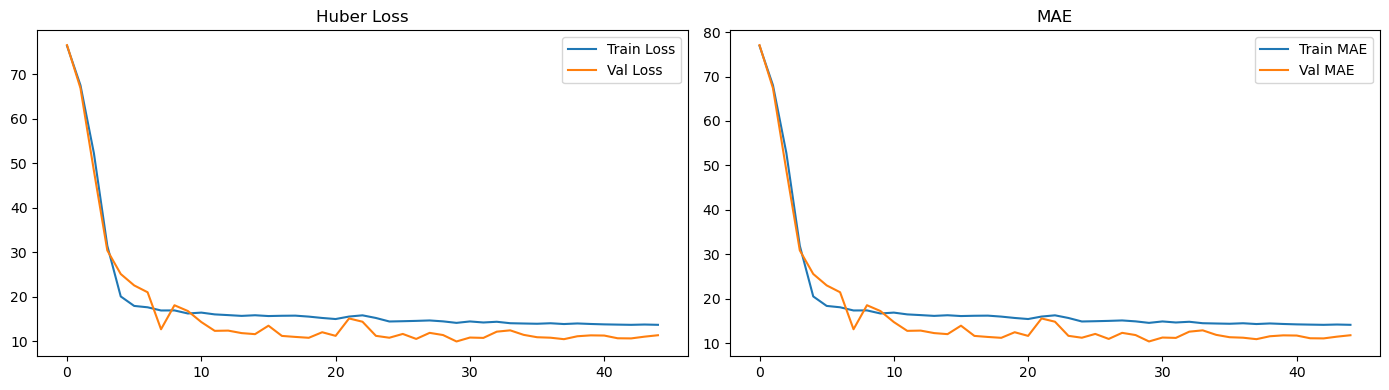

In [6]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=15,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=7, min_lr=1e-6, verbose=1)
]

history = model.fit(
    X_train, y_train,
    epochs          = 100,
    batch_size      = 256,
    validation_split= 0.15,
    callbacks       = callbacks,
    verbose         = 1
)

# ── Plot training curves ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history.history['loss'],     label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Huber Loss'); axes[0].legend()

axes[1].plot(history.history['mae'],     label='Train MAE')
axes[1].plot(history.history['val_mae'], label='Val MAE')
axes[1].set_title('MAE'); axes[1].legend()
plt.tight_layout(); plt.show()

In [7]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_pred = model.predict(X_test).flatten()
y_pred = np.clip(y_pred, 0, MAX_RUL)

mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=" * 40)
print("       MODEL EVALUATION METRICS")
print("=" * 40)
print(f"  MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"  MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"  RMSE (Root Mean Sq. Error) : {rmse:.4f}")
print("=" * 40)

from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("=" * 40)
print("       MODEL EVALUATION METRICS")
print("=" * 40)
print(f"  MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"  MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"  RMSE (Root Mean Sq. Error) : {rmse:.4f}")
print(f"  R²   (Coeff. of Determin.) : {r2:.4f}")
print("=" * 40)

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 401ms/step
       MODEL EVALUATION METRICS
  MAE  (Mean Absolute Error) : 10.3154
  MSE  (Mean Squared Error)  : 203.5515
  RMSE (Root Mean Sq. Error) : 14.2671
       MODEL EVALUATION METRICS
  MAE  (Mean Absolute Error) : 10.3154
  MSE  (Mean Squared Error)  : 203.5515
  RMSE (Root Mean Sq. Error) : 14.2671
  R²   (Coeff. of Determin.) : 0.8732


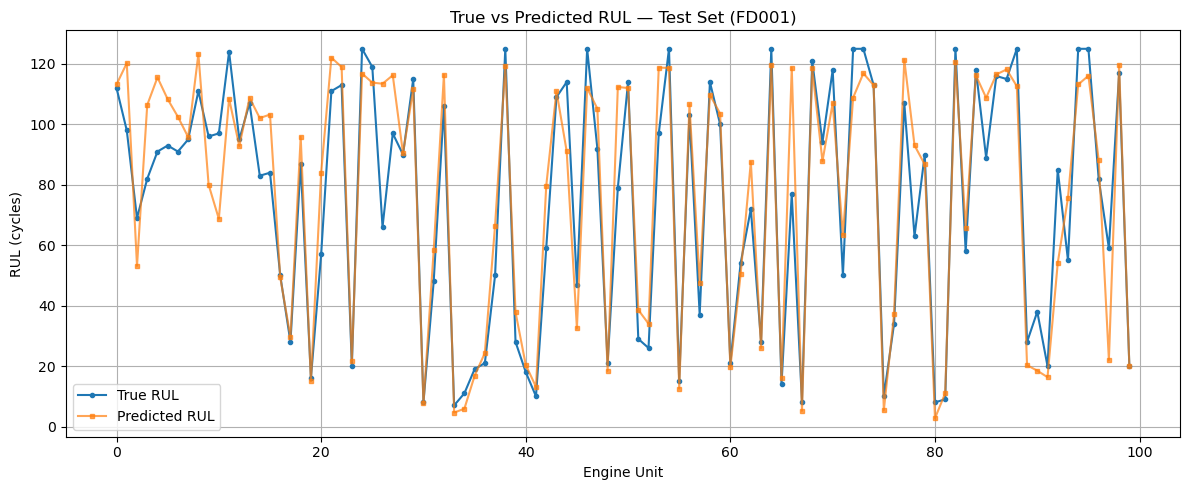

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test, label='True RUL', marker='o', markersize=3)
plt.plot(y_pred, label='Predicted RUL', marker='s', markersize=3, alpha=0.7)
plt.xlabel('Engine Unit')
plt.ylabel('RUL (cycles)')
plt.title('True vs Predicted RUL — Test Set (FD001)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

   CROSS-DOMAIN EVALUATION RESULTS

  FD001 (In-Domain)
  ────────────────────────────────────
  MAE  : 10.3154 cycles
  MSE  : 203.5515
  RMSE : 14.2671 cycles

  FD002 (Cross-Domain)
  ────────────────────────────────────
  MAE  : 52.2706 cycles
  MSE  : 3843.9006
  RMSE : 61.9992 cycles

  FD003 (Cross-Domain)
  ────────────────────────────────────
  MAE  : 20.5856 cycles
  MSE  : 850.1136
  RMSE : 29.1567 cycles

  FD004 (Cross-Domain)
  ────────────────────────────────────
  MAE  : 55.1328 cycles
  MSE  : 4261.7822
  RMSE : 65.2823 cycles



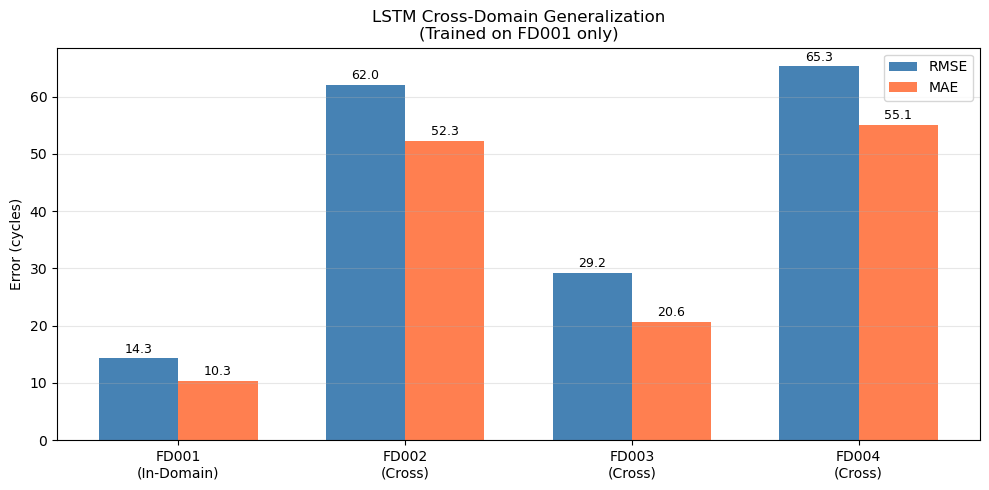

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_on_domain(test_df, rul_df, label):
    """Build test sequences and compute MAE, MSE, RMSE."""

    # Build one sequence per engine (last window)
    X = []
    for unit_id in test_df['unit'].unique():
        unit_data = test_df[test_df['unit'] == unit_id].reset_index(drop=True)
        features  = unit_data[feature_cols].values
        if len(features) >= WINDOW_SIZE:
            X.append(features[-WINDOW_SIZE:])
        else:
            pad = np.zeros((WINDOW_SIZE - len(features), len(feature_cols)))
            X.append(np.vstack([pad, features]))
    X = np.array(X)

    y_true = rul_df['RUL'].clip(upper=MAX_RUL).values
    y_pred = model.predict(X, verbose=0).flatten()
    y_pred = np.clip(y_pred, 0, MAX_RUL)

    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    print(f"\n  {label}")
    print(f"  {'─' * 36}")
    print(f"  MAE  : {mae:.4f} cycles")
    print(f"  MSE  : {mse:.4f}")
    print(f"  RMSE : {rmse:.4f} cycles")

    return mae, mse, rmse, y_true, y_pred

# ── Evaluate on all 4 subsets ─────────────────────────────────────────────────
print("=" * 40)
print("   CROSS-DOMAIN EVALUATION RESULTS")
print("=" * 40)

mae1, mse1, rmse1, yt1, yp1 = evaluate_on_domain(test_df,  rul_df,  "FD001 (In-Domain)")
mae2, mse2, rmse2, yt2, yp2 = evaluate_on_domain(test_df2, rul_df2, "FD002 (Cross-Domain)")
mae3, mse3, rmse3, yt3, yp3 = evaluate_on_domain(test_df3, rul_df3, "FD003 (Cross-Domain)")
mae4, mse4, rmse4, yt4, yp4 = evaluate_on_domain(test_df4, rul_df4, "FD004 (Cross-Domain)")

print("\n" + "=" * 40)

# ── Summary bar chart ─────────────────────────────────────────────────────────
labels  = ['FD001\n(In-Domain)', 'FD002\n(Cross)', 'FD003\n(Cross)', 'FD004\n(Cross)']
rmse_vals = [rmse1, rmse2, rmse3, rmse4]
mae_vals  = [mae1,  mae2,  mae3,  mae4]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, rmse_vals, width, label='RMSE', color='steelblue')
bars2 = ax.bar(x + width/2, mae_vals,  width, label='MAE',  color='coral')

ax.set_ylabel('Error (cycles)')
ax.set_title('LSTM Cross-Domain Generalization\n(Trained on FD001 only)')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [10]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

def apply_ocn(df, feature_cols, n_clusters, random_state=42):
    df = df.copy()
    df[feature_cols] = df[feature_cols].astype(float)
    op_cols = ['op1', 'op2', 'op3']
    kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
    df['op_cluster'] = kmeans.fit_predict(df[op_cols])
    for cluster_id in sorted(df['op_cluster'].unique()):
        mask = df['op_cluster'] == cluster_id
        cs = MinMaxScaler()
        df.loc[mask, feature_cols] = cs.fit_transform(df.loc[mask, feature_cols])
    df.drop(columns=['op_cluster', 'op3'], inplace=True, errors='ignore')
    return df

def coral_transform(source_features, target_features, blend=1.0):
    source_c = source_features - source_features.mean(axis=0)
    target_c = target_features - target_features.mean(axis=0)
    n_s, d = source_c.shape[0], source_c.shape[1]
    n_t    = target_c.shape[0]
    Cs = (source_c.T @ source_c) / (n_s - 1) + 1e-5 * np.eye(d)
    Ct = (target_c.T @ target_c) / (n_t - 1) + 1e-5 * np.eye(d)
    def mat_sqrt(M):
        eigvals, eigvecs = np.linalg.eigh(M)
        eigvals = np.maximum(eigvals, 1e-10)
        return eigvecs @ np.diag(np.sqrt(eigvals)) @ eigvecs.T
    def mat_inv_sqrt(M):
        eigvals, eigvecs = np.linalg.eigh(M)
        eigvals = np.maximum(eigvals, 1e-10)
        return eigvecs @ np.diag(1.0 / np.sqrt(eigvals)) @ eigvecs.T
    A = mat_inv_sqrt(Ct) @ mat_sqrt(Cs)
    fully_aligned = target_c @ A + source_features.mean(axis=0)
    return blend * fully_aligned + (1.0 - blend) * target_features

def apply_coral(source_df, target_df, feature_cols, blend=1.0):
    target_df = target_df.copy()
    src = source_df[feature_cols].values.astype(np.float64)
    tgt = target_df[feature_cols].values.astype(np.float64)
    target_df[feature_cols] = coral_transform(src, tgt, blend=blend)
    return target_df

def apply_baseline_correction(df, feature_cols, n_baseline_cycles=5):
    df = df.copy()
    global_mean = df[feature_cols].mean().values
    for unit_id in df['unit'].unique():
        mask = df['unit'] == unit_id
        engine_data = df.loc[mask, feature_cols].values
        n_cycles = min(n_baseline_cycles, len(engine_data))
        engine_baseline = engine_data[:n_cycles].mean(axis=0)
        df.loc[mask, feature_cols] = engine_data - engine_baseline + global_mean
    return df

def apply_ewma(df, feature_cols, alpha=0.3):
    df = df.copy()
    for unit_id in df['unit'].unique():
        mask = df['unit'] == unit_id
        df.loc[mask, feature_cols] = (
            df.loc[mask, feature_cols]
            .ewm(alpha=alpha, adjust=False)
            .mean()
            .values
        )
    return df

def build_test_sequences(df, feature_cols, window_size):
    X = []
    for unit_id in df['unit'].unique():
        unit_data = df[df['unit'] == unit_id].reset_index(drop=True)
        features  = unit_data[feature_cols].values
        if len(features) >= window_size:
            X.append(features[-window_size:])
        else:
            pad = np.zeros((window_size - len(features), len(feature_cols)))
            X.append(np.vstack([pad, features]))
    return np.array(X)

# ── Reload raw test data ───────────────────────────────────────────────────
col_names_local = ['unit', 'cycle', 'op1', 'op2', 'op3'] + \
                  [f's{i}' for i in range(1, 22)]
drop_sensors    = ['s1','s5','s6','s10','s16','s18','s19']

test_raw2 = pd.read_csv('test_FD002.txt', sep=r'\s+', header=None,
                        names=col_names_local, engine='python')
test_raw3 = pd.read_csv('test_FD003.txt', sep=r'\s+', header=None,
                        names=col_names_local, engine='python')
test_raw4 = pd.read_csv('test_FD004.txt', sep=r'\s+', header=None,
                        names=col_names_local, engine='python')

for df in [test_raw2, test_raw3, test_raw4]:
    df.drop(columns=drop_sensors, inplace=True)

# ── Build adapted dataframes ───────────────────────────────────────────────
test_adapted2 = apply_ewma(
    apply_coral(train_df, apply_ocn(test_raw2, feature_cols, n_clusters=6),
                feature_cols, blend=1.0),
    feature_cols, alpha=0.3)

test_raw3_no_op3 = test_raw3.drop(columns=['op3'], errors='ignore').copy()
test_adapted3 = apply_ewma(
    apply_baseline_correction(
        apply_coral(train_df, test_raw3_no_op3, feature_cols, blend=1.0),
        feature_cols, n_baseline_cycles=5),
    feature_cols, alpha=0.3)

test_adapted4 = apply_ewma(
    apply_baseline_correction(
        apply_coral(train_df, apply_ocn(test_raw4, feature_cols, n_clusters=6),
                    feature_cols, blend=0.6),
        feature_cols, n_baseline_cycles=5),
    feature_cols, alpha=0.5)

# ── Compute predictions ────────────────────────────────────────────────────
X2 = build_test_sequences(test_adapted2, feature_cols, WINDOW_SIZE)
X3 = build_test_sequences(test_adapted3, feature_cols, WINDOW_SIZE)
X4 = build_test_sequences(test_adapted4, feature_cols, WINDOW_SIZE)

cnnlstm_yp_fd001 = np.clip(model.predict(X_test, verbose=0).flatten(), 0, MAX_RUL)
cnnlstm_yp_fd002 = np.clip(model.predict(X2,     verbose=0).flatten(), 0, MAX_RUL)
cnnlstm_yp_fd003 = np.clip(model.predict(X3,     verbose=0).flatten(), 0, MAX_RUL)
cnnlstm_yp_fd004 = np.clip(model.predict(X4,     verbose=0).flatten(), 0, MAX_RUL)

# ── Save ───────────────────────────────────────────────────────────────────
np.save('cnnlstm_preds_fd001.npy', cnnlstm_yp_fd001)
np.save('cnnlstm_preds_fd002.npy', cnnlstm_yp_fd002)
np.save('cnnlstm_preds_fd003.npy', cnnlstm_yp_fd003)
np.save('cnnlstm_preds_fd004.npy', cnnlstm_yp_fd004)

print("CNN-LSTM predictions saved successfully.")
print(f"  FD001: {cnnlstm_yp_fd001.shape}  |  FD002: {cnnlstm_yp_fd002.shape}")
print(f"  FD003: {cnnlstm_yp_fd003.shape}  |  FD004: {cnnlstm_yp_fd004.shape}")

CNN-LSTM predictions saved successfully.
  FD001: (100,)  |  FD002: (259,)
  FD003: (100,)  |  FD004: (248,)


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# ── Compute CNN-LSTM metrics for all 4 datasets ───────────────────────────────
# This cell must run AFTER Cell 9 (domain adaptation) so that
# test_adapted2, test_adapted3, test_adapted4 already exist

def compute_metrics(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

def phm_score(y_true, y_pred):
    d = y_pred - y_true
    scores = np.where(d < 0,
                      np.exp(-d / 13) - 1,
                      np.exp( d / 10) - 1)
    return np.sum(scores)

def build_test_sequences(df, feature_cols, window_size):
    X = []
    for unit_id in df['unit'].unique():
        unit_data = df[df['unit'] == unit_id].reset_index(drop=True)
        features  = unit_data[feature_cols].values
        if len(features) >= window_size:
            X.append(features[-window_size:])
        else:
            pad = np.zeros((window_size - len(features), len(feature_cols)))
            X.append(np.vstack([pad, features]))
    return np.array(X)

# ── FD001 (in-domain, no adaptation needed) ───────────────────────────────────
yp1_cnn   = np.clip(model.predict(X_test, verbose=0).flatten(), 0, MAX_RUL)
mae1_cnn, mse1_cnn, rmse1_cnn, r2_1_cnn = compute_metrics(y_test, yp1_cnn)
phm1_cnn  = phm_score(y_test, yp1_cnn)

# ── FD002 (adapted) ───────────────────────────────────────────────────────────
X2_cnn    = build_test_sequences(test_adapted2, feature_cols, WINDOW_SIZE)
yp2_cnn   = np.clip(model.predict(X2_cnn, verbose=0).flatten(), 0, MAX_RUL)
y2_true   = rul_df2['RUL'].clip(upper=MAX_RUL).values
mae2_cnn, mse2_cnn, rmse2_cnn, r2_2_cnn = compute_metrics(y2_true, yp2_cnn)
phm2_cnn  = phm_score(y2_true, yp2_cnn)

# ── FD003 (adapted) ───────────────────────────────────────────────────────────
X3_cnn    = build_test_sequences(test_adapted3, feature_cols, WINDOW_SIZE)
yp3_cnn   = np.clip(model.predict(X3_cnn, verbose=0).flatten(), 0, MAX_RUL)
y3_true   = rul_df3['RUL'].clip(upper=MAX_RUL).values
mae3_cnn, mse3_cnn, rmse3_cnn, r2_3_cnn = compute_metrics(y3_true, yp3_cnn)
phm3_cnn  = phm_score(y3_true, yp3_cnn)

# ── FD004 (adapted) ───────────────────────────────────────────────────────────
X4_cnn    = build_test_sequences(test_adapted4, feature_cols, WINDOW_SIZE)
yp4_cnn   = np.clip(model.predict(X4_cnn, verbose=0).flatten(), 0, MAX_RUL)
y4_true   = rul_df4['RUL'].clip(upper=MAX_RUL).values
mae4_cnn, mse4_cnn, rmse4_cnn, r2_4_cnn = compute_metrics(y4_true, yp4_cnn)
phm4_cnn  = phm_score(y4_true, yp4_cnn)

# ── Print CNN-LSTM results ────────────────────────────────────────────────────
print("=" * 62)
print("  CNN-LSTM RESULTS SUMMARY")
print("=" * 62)
print(f"{'Dataset':<16} {'RMSE':>7} {'MAE':>7} {'MSE':>10} "
      f"{'R²':>7} {'PHM':>10}")
print("-" * 62)
print(f"{'FD001 (in-domain)':<16} {rmse1_cnn:>7.4f} {mae1_cnn:>7.4f} "
      f"{mse1_cnn:>10.4f} {r2_1_cnn:>7.4f} {phm1_cnn:>10.2f}")
print(f"{'FD002 (adapted)':<16} {rmse2_cnn:>7.4f} {mae2_cnn:>7.4f} "
      f"{mse2_cnn:>10.4f} {r2_2_cnn:>7.4f} {phm2_cnn:>10.2f}")
print(f"{'FD003 (adapted)':<16} {rmse3_cnn:>7.4f} {mae3_cnn:>7.4f} "
      f"{mse3_cnn:>10.4f} {r2_3_cnn:>7.4f} {phm3_cnn:>10.2f}")
print(f"{'FD004 (adapted)':<16} {rmse4_cnn:>7.4f} {mae4_cnn:>7.4f} "
      f"{mse4_cnn:>10.4f} {r2_4_cnn:>7.4f} {phm4_cnn:>10.2f}")
print("=" * 62)
print("CNN-LSTM metrics computed — ready for comparison cell.")

  CNN-LSTM RESULTS SUMMARY
Dataset             RMSE     MAE        MSE      R²        PHM
--------------------------------------------------------------
FD001 (in-domain) 14.2671 10.3154   203.5515  0.8732     430.36
FD002 (adapted)  24.5650 18.9390   603.4394  0.6727    3172.27
FD003 (adapted)  33.0649 25.4637  1093.2854  0.2873    3901.28
FD004 (adapted)  46.6368 38.4942  2174.9924 -0.1773   27007.67
CNN-LSTM metrics computed — ready for comparison cell.


  MODEL COMPARISON — LSTM vs CNN-LSTM
  (Both trained on FD001, tested with Hybrid UDA on FD002-FD004)
Dataset    Metric       LSTM   CNN-LSTM     Better
--------------------------------------------------------------------------------
FD001      RMSE      13.4387    14.2671       LSTM
           MAE        9.7693    10.3154       LSTM
           MSE      180.5976   203.5515       LSTM
           R²         0.8875     0.8732       LSTM
           PHM      366.1000   430.3619       LSTM
--------------------------------------------------------------------------------
FD002      RMSE      23.7516    24.5650       LSTM
           MAE       18.2790    18.9390       LSTM
           MSE      564.1383   603.4394       LSTM
           R²         0.6940     0.6727       LSTM
           PHM     2838.7000  3172.2664       LSTM
--------------------------------------------------------------------------------
FD003      RMSE      33.7757    33.0649   CNN-LSTM
           MAE       27.4762    25.4637   

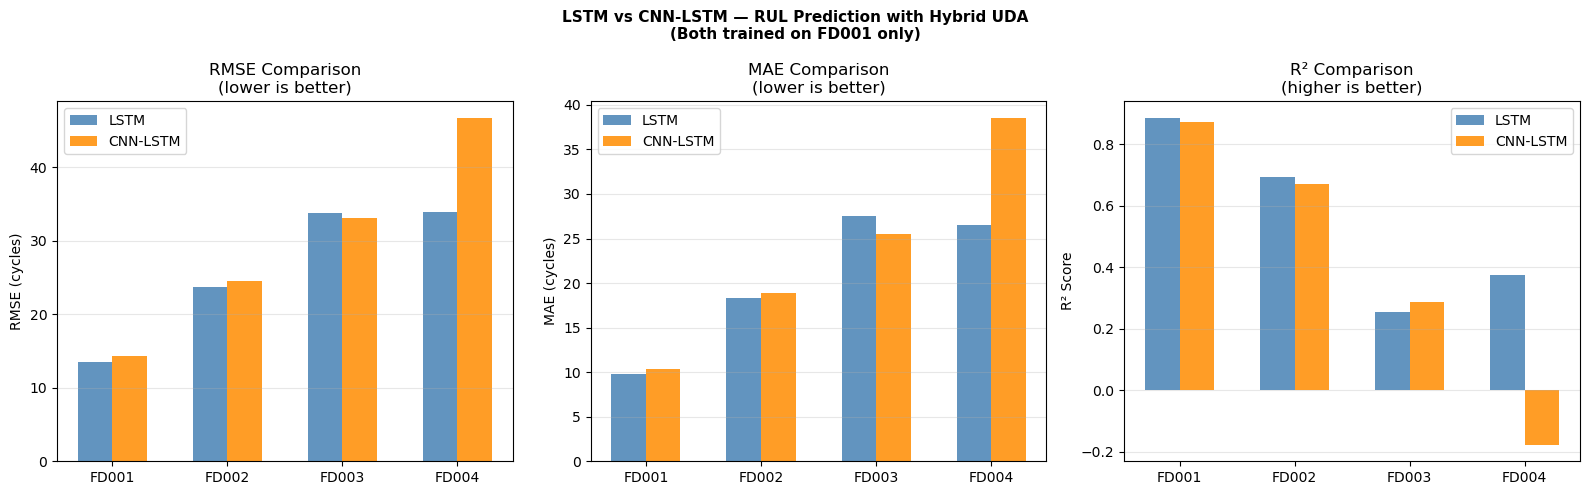

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ── LSTM results (from your Version3 notebook) ────────────────────────────────
lstm_results = {
    'FD001': (13.4387,  9.7693,  180.5976, 0.8875,    366.10),
    'FD002': (23.7516, 18.2790,  564.1383, 0.6940,   2838.70),
    'FD003': (33.7757, 27.4762, 1140.7979, 0.2563,   3699.25),
    'FD004': (33.9454, 26.5644, 1152.2883, 0.3763,  10458.02),
}

# ── CNN-LSTM results (computed in this notebook) ──────────────────────────────
# Replace these with your actual CNN-LSTM results after running the notebook
cnnlstm_results = {
    'FD001': (rmse1_cnn, mae1_cnn, mse1_cnn, r2_1_cnn, phm1_cnn),
    'FD002': (rmse2_cnn, mae2_cnn, mse2_cnn, r2_2_cnn, phm2_cnn),
    'FD003': (rmse3_cnn, mae3_cnn, mse3_cnn, r2_3_cnn, phm3_cnn),
    'FD004': (rmse4_cnn, mae4_cnn, mse4_cnn, r2_4_cnn, phm4_cnn),
}

# ── Print comparison table ────────────────────────────────────────────────────
print("=" * 80)
print("  MODEL COMPARISON — LSTM vs CNN-LSTM")
print("  (Both trained on FD001, tested with Hybrid UDA on FD002-FD004)")
print("=" * 80)
print(f"{'Dataset':<10} {'Metric':<6} {'LSTM':>10} {'CNN-LSTM':>10} {'Better':>10}")
print("-" * 80)

for name in ['FD001', 'FD002', 'FD003', 'FD004']:
    lstm = lstm_results[name]
    cnn  = cnnlstm_results[name]
    metrics = ['RMSE', 'MAE', 'MSE', 'R²', 'PHM']

    for i, metric in enumerate(metrics):
        lstm_val = lstm[i]
        cnn_val  = cnn[i]

        # For R², higher is better. For everything else, lower is better.
        if metric == 'R²':
            better = 'CNN-LSTM' if cnn_val > lstm_val else 'LSTM'
        else:
            better = 'CNN-LSTM' if cnn_val < lstm_val else 'LSTM'

        print(f"{name if i==0 else '':<10} {metric:<6} "
              f"{lstm_val:>10.4f} {cnn_val:>10.4f} {better:>10}")

    print("-" * 80)

print("=" * 80)

# ── Bar chart comparison ──────────────────────────────────────────────────────
datasets = ['FD001', 'FD002', 'FD003', 'FD004']
rmse_lstm = [lstm_results[k][0] for k in datasets]
rmse_cnn  = [cnnlstm_results[k][0] for k in datasets]
mae_lstm  = [lstm_results[k][1] for k in datasets]
mae_cnn   = [cnnlstm_results[k][1] for k in datasets]
r2_lstm   = [lstm_results[k][3] for k in datasets]
r2_cnn    = [cnnlstm_results[k][3] for k in datasets]

x     = np.arange(len(datasets))
width = 0.3

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# RMSE
axes[0].bar(x - width/2, rmse_lstm, width, label='LSTM',
            color='steelblue', alpha=0.85)
axes[0].bar(x + width/2, rmse_cnn,  width, label='CNN-LSTM',
            color='darkorange', alpha=0.85)
axes[0].set_title('RMSE Comparison\n(lower is better)')
axes[0].set_ylabel('RMSE (cycles)')
axes[0].set_xticks(x); axes[0].set_xticklabels(datasets)
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)

# MAE
axes[1].bar(x - width/2, mae_lstm, width, label='LSTM',
            color='steelblue', alpha=0.85)
axes[1].bar(x + width/2, mae_cnn,  width, label='CNN-LSTM',
            color='darkorange', alpha=0.85)
axes[1].set_title('MAE Comparison\n(lower is better)')
axes[1].set_ylabel('MAE (cycles)')
axes[1].set_xticks(x); axes[1].set_xticklabels(datasets)
axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)

# R²
axes[2].bar(x - width/2, r2_lstm, width, label='LSTM',
            color='steelblue', alpha=0.85)
axes[2].bar(x + width/2, r2_cnn,  width, label='CNN-LSTM',
            color='darkorange', alpha=0.85)
axes[2].set_title('R² Comparison\n(higher is better)')
axes[2].set_ylabel('R² Score')
axes[2].set_xticks(x); axes[2].set_xticklabels(datasets)
axes[2].legend(); axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('LSTM vs CNN-LSTM — RUL Prediction with Hybrid UDA\n'
             '(Both trained on FD001 only)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# EXPORT CNN-LSTM RESULTS TO EXCEL
# Saves two sheets:
#   Sheet 1 — LSTM vs CNN-LSTM Comparison (all datasets, all metrics)
#   Sheet 2 — CNN-LSTM Full Results Summary
#
# Requires: Cell 11 (metrics) and Cell 12 (comparison) to have run first.
# ══════════════════════════════════════════════════════════════════════════════

import pandas as pd

datasets = ['FD001', 'FD002', 'FD003', 'FD004']
metrics  = ['RMSE', 'MAE', 'MSE', 'R²', 'PHM']

# ── Sheet 1: LSTM vs CNN-LSTM Comparison ─────────────────────────────────────
rows_comparison = []
for ds in datasets:
    lstm = lstm_results[ds]      # (RMSE, MAE, MSE, R², PHM)
    cnn  = cnnlstm_results[ds]

    for i, metric in enumerate(metrics):
        lv, cv = lstm[i], cnn[i]
        if metric == 'R²':
            better = 'CNN-LSTM' if cv > lv else 'LSTM'
        else:
            better = 'CNN-LSTM' if cv < lv else 'LSTM'

        rows_comparison.append({
            'Dataset'    : ds,
            'Metric'     : metric,
            'LSTM'       : round(lv, 4),
            'CNN-LSTM'   : round(cv, 4),
            'Better Model': better,
        })

df_comparison = pd.DataFrame(rows_comparison)

# ── Sheet 2: CNN-LSTM Full Summary ────────────────────────────────────────────
rows_cnn = []
for ds, (rmse, mae, mse, r2, phm) in cnnlstm_results.items():
    rows_cnn.append({
        'Dataset': ds,
        'RMSE'   : round(rmse, 4),
        'MAE'    : round(mae,  4),
        'MSE'    : round(mse,  4),
        'R²'     : round(r2,   4),
        'PHM'    : round(phm,  2),
    })

df_cnn = pd.DataFrame(rows_cnn)

# ── Write to Excel ───────────────────────────────────────────────────────────────
filename = 'CNNLSTM_Results.xlsx'

with pd.ExcelWriter(filename, engine='openpyxl') as writer:
    df_comparison.to_excel(writer, sheet_name='LSTM vs CNN-LSTM', index=False)
    df_cnn.to_excel(writer,        sheet_name='CNN-LSTM Summary', index=False)

print(f"✓ Excel file saved: {filename}")
print(f"  Sheet 1 — LSTM vs CNN-LSTM : {len(df_comparison)} rows")
print(f"  Sheet 2 — CNN-LSTM Summary : {len(df_cnn)} rows")
